<a href="https://colab.research.google.com/github/febrianucup/PCVK-CItra-Vision-Computer/blob/main/JS9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

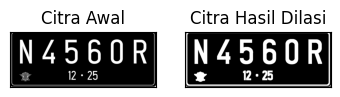

In [31]:
def dilasi_citra(F, w):
  p,q=F.shape

  imgD=np.zeros((p,q), dtype=np.uint8)

  SED=np.ones((w,w), dtype=np.uint8)
  constant1=(w-1)//2

  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

img_d= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0)
if img_d is None:
    print("Error: Image not found. Please verify the file path on your Google Drive.")
else:
    ret, thresh = cv.threshold(img_d, 125, 200, cv.THRESH_BINARY)

    w=9
    imgD = dilasi_citra(thresh,w)
    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


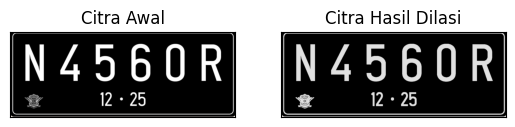

In [32]:
img = cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg')
#img = cv.imread('morp.jpg',0)
ret, thresh = cv.threshold(img, 127, 225, cv.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv.dilate(thresh,kernel,iterations = 1)
print(kernel)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

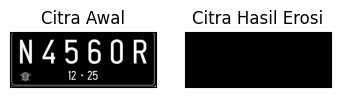

In [33]:
def erosi_citra(F,k):
  m,n= F.shape
  #Generate structure element erosi (SE)
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)
  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE
img_e= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0) #
ret1, thresh1 = cv.threshold(img_e, 175, 225, cv.THRESH_BINARY)
k=99
imgE = erosi_citra(thresh1,k)
plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

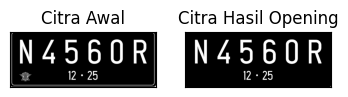

In [34]:
def erosi_citra(F, k):
  m, n = F.shape
  SE = np.ones((k, k), dtype=np.uint8)
  constant = (k - 1) // 2
  imgE = np.zeros((m, n), dtype=np.uint8)
  for i in range(constant, m - constant):
    for j in range(constant, n - constant):
      temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
      product = temp * SE
      imgE[i, j] = np.min(product)
  return imgE

def dilasi_citra(F, w):
  p, q = F.shape
  imgD = np.zeros((p, q), dtype=np.uint8)
  SED = np.ones((w, w), dtype=np.uint8)
  constant1 = (w - 1) // 2
  for i in range(constant1, p - constant1):
    for j in range(constant1, q - constant1):
      temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
      product = temp * SED
      imgD[i, j] = np.max(product)
  return imgD

img_o = cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg', 0)
if img_o is None:
    print("Error: Image not found. Please verify the file path.")
else:
    reto, thresho = cv.threshold(img_o, 127, 225, cv.THRESH_BINARY)
    k = 7
    imgO = dilasi_citra(erosi_citra(thresho, k), k)
    plt.subplot(131), plt.imshow(img_o, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgO, cmap='gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.show()

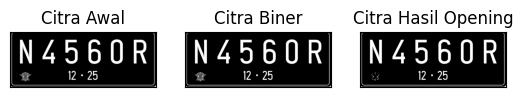

In [35]:
img = cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0)
ret, thresh = cv.threshold(img, 127, 225, cv.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
openn = cv.morphologyEx(thresh,cv.MORPH_OPEN, kernel)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(openn,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

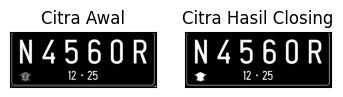

In [36]:
img_c= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0) #
retc, threshc = cv.threshold(img_c, 127, 225, cv.THRESH_BINARY)
k=7
imgC = erosi_citra(dilasi_citra(threshc,k),k)
plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgC,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

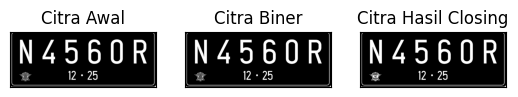

In [37]:
img = cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0)
ret, thresh = cv.threshold(img, 127, 225, cv.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
closs = cv.morphologyEx(thresh,cv.MORPH_CLOSE, kernel)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(closs,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 3


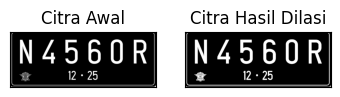

SED = Cross 5


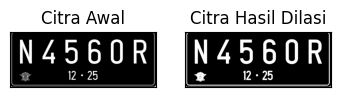

In [38]:
def dilasi_citra(F,w):
  #size image
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  #Generate structure element dilasi (SED)
  # SED= np.ones((w,w), dtype=np.uint8)
  SED = np.array([[0, 1, 0],
  [1, 1, 1],
  [0, 1, 0]], dtype = np.uint8)
  constant1= (w-1)//2
  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

print('SED = Cross 3')
img_d= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0)
ret, thresh = cv.threshold(img_d, 127, 225, cv.THRESH_BINARY)
w=3
imgD = dilasi_citra(thresh,w)
plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

def dilasi_citra(F,w):
#size image
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  SED = np.array([[0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0],
                  [1, 1, 1, 1, 1],
                  [0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0]], dtype = np.uint8)
  constant1= (w-1)//2
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

print('SED = Cross 5')
img_d= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0)
ret, thresh = cv.threshold(img_d, 127, 225, cv.THRESH_BINARY)
w=5
imgD = dilasi_citra(thresh,w)
plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Circle 3


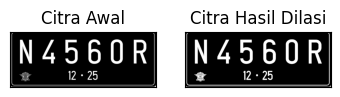

SED = Circle 5


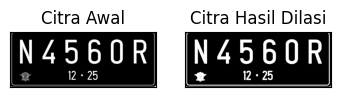

In [39]:
def dilasi_citra(F,w):
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  SED= cv.getStructuringElement(cv.MORPH_ELLIPSE,(w,w))
  constant1= (w-1)//2
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD
print('SED = Circle 3')
img_d= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0)
ret, thresh = cv.threshold(img_d, 127, 225, cv.THRESH_BINARY)
w=3
imgD = dilasi_citra(thresh,w)
plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()
print('SED = Circle 5')
img_d= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0)
ret, thresh = cv.threshold(img_d, 127, 225, cv.THRESH_BINARY)
w=5
imgD = dilasi_citra(thresh,w)
plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Rectangle 3x5


(<Axes: >, <matplotlib.image.AxesImage at 0x79f853d3e490>)

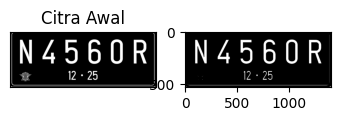

In [40]:
def erosi_citra(F,p,l):
  #size image
  m,n= F.shape
  #Generate structure element erosi (SE)
  SE = cv.getStructuringElement(cv.MORPH_RECT,(p,l)) #SE persegi panjang
  constant1= (l-1)//2
  constant2= (p-1)//2
  # print(SE)
  imgE= np.zeros((m,n), dtype=np.uint8)
  #Proses Erosi
  for i in range(constant1, m-constant1):
    for j in range(constant2,n-constant2):
      temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE
print('SE = Rectangle 3x5')
img_e= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0) #
ret1, thresh1 = cv.threshold(img_e, 127, 225, cv.THRESH_BINARY)
p=5
l=3
imgE = erosi_citra(thresh1,p,l)
plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')

SE = Rectangle 3x5


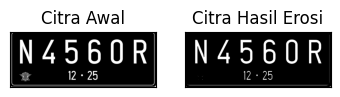

SE = Rectangle 5x7


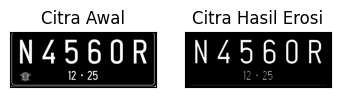

In [41]:
def erosi_citra(F,p,l):
  #size image
  m,n= F.shape
  #Generate structure element erosi (SE)
  SE = cv.getStructuringElement(cv.MORPH_RECT,(p,l)) #SE persegi panjang
  constant1= (l-1)//2
  constant2= (p-1)//2
  # print(SE)
  imgE= np.zeros((m,n), dtype=np.uint8)
  #Proses Erosi
  for i in range(constant1, m-constant1):
    for j in range(constant2,n-constant2):
      temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE
print('SE = Rectangle 3x5')
img_e= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0) #
ret1, thresh1 = cv.threshold(img_e, 127, 225, cv.THRESH_BINARY)
p=5
l=3
imgE = erosi_citra(thresh1,p,l)
plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()
print('SE = Rectangle 5x7')
img_e= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0) #
ret1, thresh1 = cv.threshold(img_e, 127, 225, cv.THRESH_BINARY)
p=7
l=5
imgE = erosi_citra(thresh1,p,l)
plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Line Vertikal 3


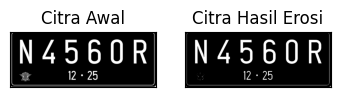

SE = Line Vertikal 5


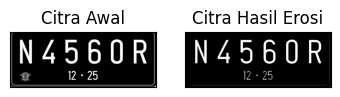

In [42]:
def erosi_citra(F,k):
  #size image
  m,n= F.shape
  #Generate structure element erosi (SE)
  SE = cv.getStructuringElement(cv.MORPH_ELLIPSE,(1,k)) #SE line vertikal
  constant= (k-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)
  for i in range(constant, m-constant):
   for j in range(constant,n-constant):
    temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
    product= temp*SE
    imgE[i,j]= np.min(product)
  return imgE
print('SE = Line Vertikal 3')
img_e= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0) #
ret1, thresh1 = cv.threshold(img_e, 127, 225, cv.THRESH_BINARY)
k=3
imgE = erosi_citra(thresh1,k)
plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()
print('SE = Line Vertikal 5')
img_e= cv.imread('/content/drive/MyDrive/PCVK/Platnomor.jpeg',0) #
ret1, thresh1 = cv.threshold(img_e, 127, 225, cv.THRESH_BINARY)
k=5
imgE = erosi_citra(thresh1,k)
plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

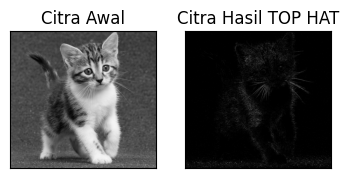

In [43]:
# Getting the kernel to be used in Top-Hat
filterSize =(3, 3)
kernel = cv.getStructuringElement(cv.MORPH_RECT,
filterSize)
# Reading the image named 'input.jpg'
img = cv.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
# Applying the Top-Hat operation
tophat_img = cv.morphologyEx(img,
              cv.MORPH_TOPHAT,
              kernel)
#cv.imshow("original", img)
#cv.imshow("tophat", tophat_img)
#cv.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

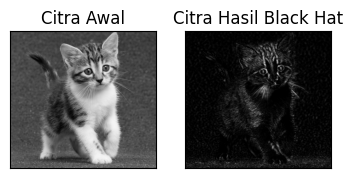

In [44]:
filterSize =(3, 3)
kernel = cv.getStructuringElement(cv.MORPH_RECT, filterSize)
# Reading the image named 'input.jpg'
img = cv.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
# Applying the Black-Hat operation
#tophat_img = cv.morphologyEx(img,cv.MORPH_BLACKHAT, kernel)
Kernel = cv.getStructuringElement(cv.MORPH_RECT, (13, 5))
blackhat = cv.morphologyEx(img, cv.MORPH_BLACKHAT, Kernel)
#cv.imshow("original", input_image)
#cv.imshow("tophat", tophat_img)
#cv.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

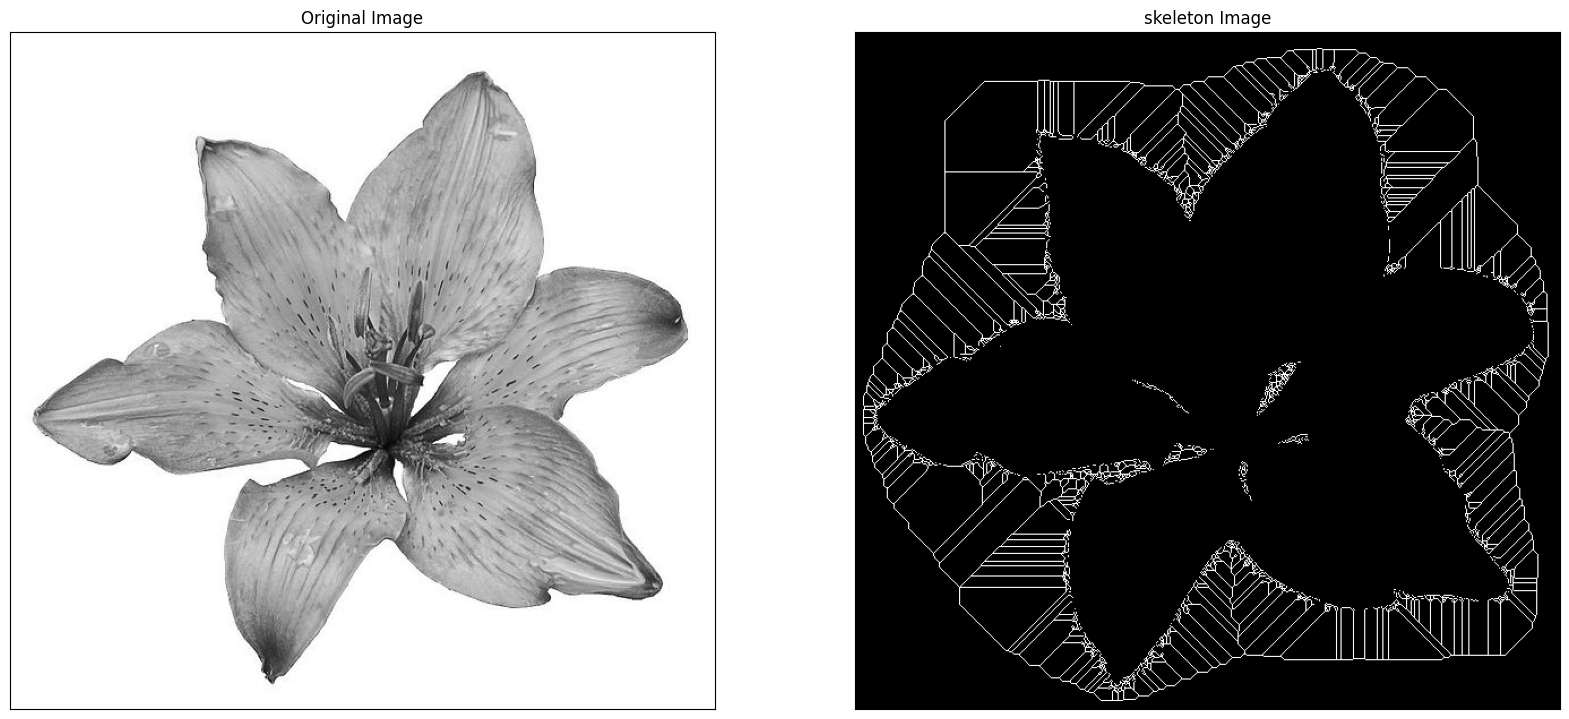

In [45]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize
# read image
img = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg',0)
binary = img > filters.threshold_triangle(img)
# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0
# skeletonize image
skeleton = skeletonize(binary_cp)
# print images
plt.figure(figsize=(20,20))
plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary and bin_skeleton.png")
plt.show()

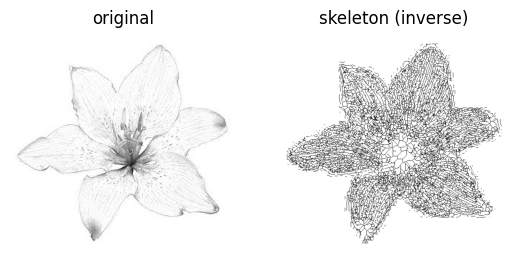

In [46]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize
# read image
img = io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')[..., 0]
# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)
# skeletonize image
skeleton = skeletonize(binary)
# print images
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()
# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

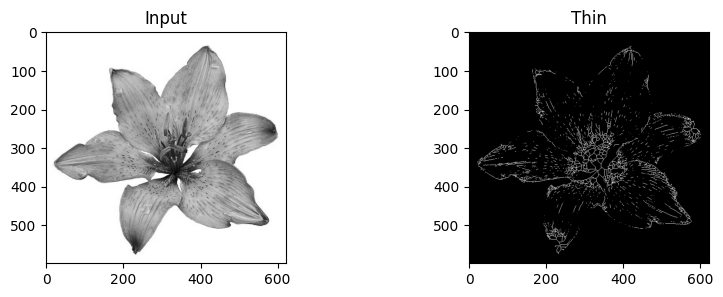

In [47]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt
image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)
f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.savefig('/tmp/char_out.png')
plt.show()

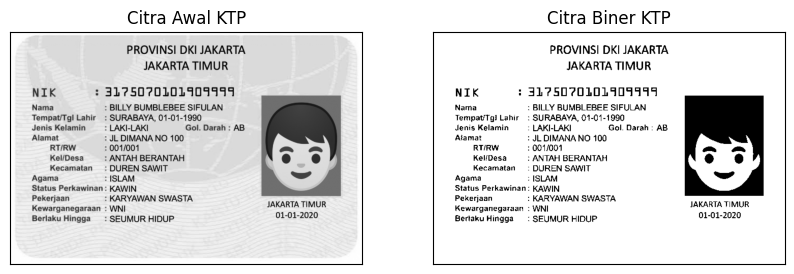

In [49]:
# Membaca citra KTP dari Google Drive (sesuaikan path direktori Anda)
img = cv.imread('/content/drive/MyDrive/PCVK/Images/ktp1.jpg', 0)

# Jika gambar berwarna, pastikan dibaca dengan benar, lalu ubah ke biner (thresholding)
if img is None:
    # Fallback jika nama file berbeda
    img = cv.imread('/content/drive/MyDrive/PCVK/Images/ktp.png', 0)

# Melakukan Thresholding Otsu atau Binary biasa untuk mendapatkan citra biner yang kontras
ret, thresh = cv.threshold(img, 127, 255, cv.THRESH_BINARY)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Citra Awal KTP')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner KTP')
plt.xticks([]), plt.yticks([])
plt.show()

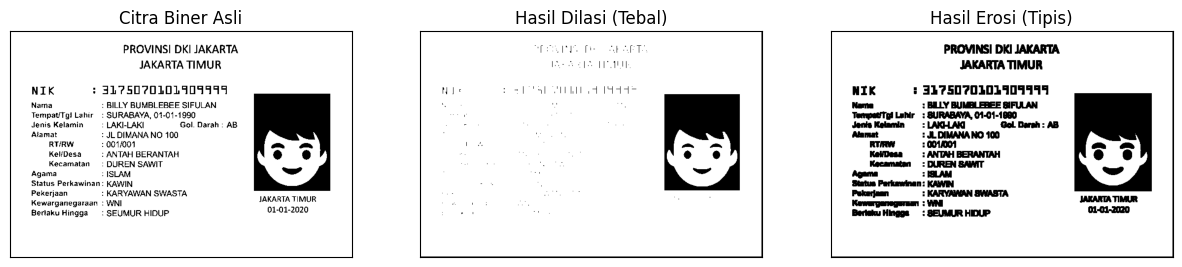

In [50]:
# Fungsi Dilasi Tanpa Library Morphology OpenCV
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# Fungsi Erosi Tanpa Library Morphology OpenCV
def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
# Menggunakan nilai minimum untuk erosi
            imgE[i, j] = np.min(product)
    return imgE

# Penerapan pada Citra KTP
w_kernel = 3
img_dilation = dilasi_citra(thresh, w_kernel)
img_erosion = erosi_citra(thresh, w_kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner Asli')
plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(img_dilation, cmap='gray'), plt.title('Hasil Dilasi (Tebal)')
plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(img_erosion, cmap='gray'), plt.title('Hasil Erosi (Tipis)')
plt.xticks([]), plt.yticks([])
plt.show()

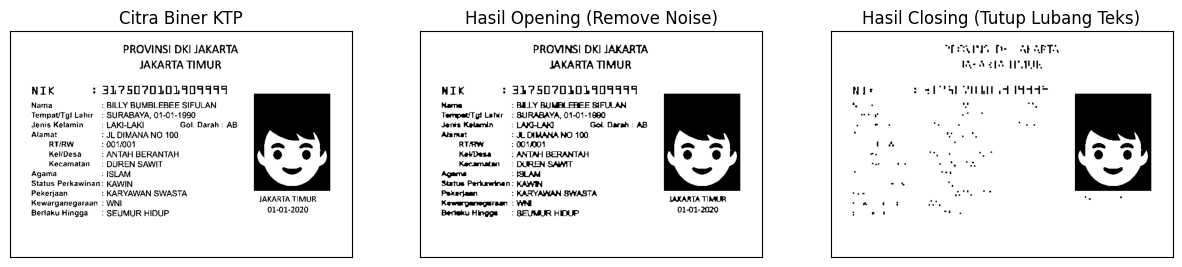

In [51]:
# Menggunakan OpenCV morphologyEx
kernel_oc = np.ones((3, 3), np.uint8)

# Opening (Erosi dilanjutkan Dilasi)
opening_ktp = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel_oc)

# Closing (Dilasi dilanjutkan Erosi)
closing_ktp = cv.morphologyEx(thresh, cv.MORPH_CLOSE, kernel_oc)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(thresh, cmap='gray'), plt.title('Citra Biner KTP')
plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(opening_ktp, cmap='gray'), plt.title('Hasil Opening (Remove Noise)')
plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closing_ktp, cmap='gray'), plt.title('Hasil Closing (Tutup Lubang Teks)')
plt.xticks([]), plt.yticks([])
plt.show()